# Geometrie und Trigonometrie

## 02 - Trigonometrie 2: Einheitskreis und Funktionen

Der Einheitskreis ($P = (\cos\alpha, \sin\alpha)$ auf dem Kreis mit $r = 1$) erweitert Sinus und Cosinus auf alle Winkel — periodische Funktionen mit Periode $2\pi$ und Amplitude $1$, Bogenmaß ($\text{rad} = \text{deg} \cdot \pi/180$), Quadrantenvorzeichen, fundamentale Identität $\sin^2\alpha + \cos^2\alpha = 1$ und Lösen trigonometrischer Gleichungen.

> Vorausgesetzt: Sinus/Cosinus im rechtwinkligen Dreieck (04_Trigonometrie/01).

### Lernziele

- Du verstehst den **Einheitskreis** als Erweiterung des Dreiecks.
- Du lernst die **Graphen** von Sinus und Cosinus kennen (Wellenform).
- Du verstehst **Symmetrien** (warum es oft zwei Lösungen für einen Winkel gibt).
- Du lernst Strategien zum **Lösen trigonometrischer Gleichungen** (Substitution).

---

## 1. Der Einheitskreis (The Unit Circle)

Statt eines beliebigen Dreiecks betrachten wir einen Kreis mit Radius $r=1$ im Koordinatensystem.
Der Mittelpunkt liegt bei $(0|0)$.

Jeder Winkel $\alpha$ (gemessen von der positiven x-Achse gegen den Uhrzeigersinn) definiert einen Punkt $P$ auf dem Kreis:

$$P = (\cos\alpha,\ \sin\alpha)$$

- Die **x-Koordinate** dieses Punktes ist der **Cosinus**.
- Die **y-Koordinate** dieses Punktes ist der **Sinus**.

Damit können wir plötzlich auch den Sinus von $120°$ oder $-30°$ bestimmen - das Dreieck ist nicht mehr nötig.

### Wertetabelle (wichtige Winkel)

| $\alpha$ | $0°$ | $30°$ | $45°$ | $60°$ | $90°$ | $180°$ | $270°$ | $360°$ |
|---|---|---|---|---|---|---|---|---|
| $\sin\alpha$ | $0$ | $\frac{1}{2}$ | $\frac{\sqrt2}{2}$ | $\frac{\sqrt3}{2}$ | $1$ | $0$ | $-1$ | $0$ |
| $\cos\alpha$ | $1$ | $\frac{\sqrt3}{2}$ | $\frac{\sqrt2}{2}$ | $\frac{1}{2}$ | $0$ | $-1$ | $0$ | $1$ |
| $\tan\alpha$ | $0$ | $\frac{\sqrt3}{3}$ | $1$ | $\sqrt3$ | - | $0$ | - | $0$ |

### Bogenmaß (Radians)

Neben der Gradangabe gibt es das **Bogenmaß**: Die Bogenlänge auf dem Einheitskreis.

$$\text{rad} = \text{deg} \cdot \frac{\pi}{180}$$

| Grad | $0°$ | $30°$ | $45°$ | $60°$ | $90°$ | $180°$ | $360°$ |
|---|---|---|---|---|---|---|---|
| Bogenmaß | $0$ | $\frac{\pi}{6}$ | $\frac{\pi}{4}$ | $\frac{\pi}{3}$ | $\frac{\pi}{2}$ | $\pi$ | $2\pi$ |

> **Merke:** In der Mathematik und Physik wird fast immer das Bogenmaß verwendet. Python-Funktionen wie `math.sin()` erwarten ebenfalls Bogenmaß.

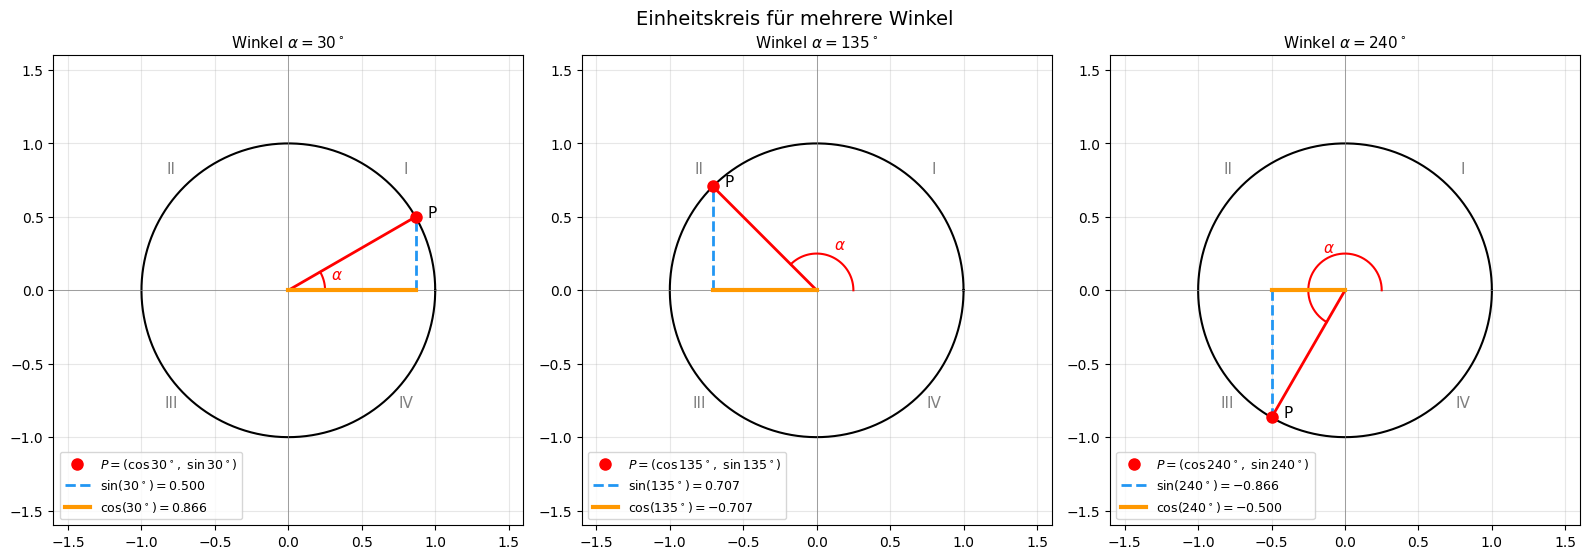

In [16]:
import numpy as np
import matplotlib.pyplot as plt

# --- Visualisierung: Der Einheitskreis ---

def plot_einheitskreis(ax, winkel_grad=45):
    """Zeigt den Einheitskreis mit einem Punkt P und dessen sin/cos-Projektion."""
    alpha = np.radians(winkel_grad)

    # Einheitskreis zeichnen
    theta = np.linspace(0, 2 * np.pi, 300)
    ax.plot(np.cos(theta), np.sin(theta), 'k-', linewidth=1.5)

    # Achsen
    ax.axhline(0, color='grey', linewidth=0.5)
    ax.axvline(0, color='grey', linewidth=0.5)

    # Punkt P
    px, py = np.cos(alpha), np.sin(alpha)
    ax.plot(
        px,
        py,
        'ro',
        markersize=8,
        zorder=5,
        label=f'$P = (\\cos {winkel_grad}^\\circ,\\ \\sin {winkel_grad}^\\circ)$',
    )
    ax.annotate(
        'P',
        xy=(px, py),

        xytext=(px + 0.08, py),
        fontsize=11,
    )

    # Radius (Hypotenuse)
    ax.plot([0, px], [0, py], 'r-', linewidth=2)

    # Winkelbogen
    bogen = np.linspace(0, alpha, 50)
    r_bogen = 0.25
    ax.plot(r_bogen * np.cos(bogen), r_bogen * np.sin(bogen), 'r-', linewidth=1.5)
    ax.text(0.3 * np.cos(alpha / 2), 0.3 * np.sin(alpha / 2), f'$\\alpha$', fontsize=11, color='red')

    # Projektionen
    ax.plot([px, px], [0, py], '--', color='#2196F3', linewidth=2, label=f'$\\sin({winkel_grad}^\\circ) = {py:.3f}$')
    ax.plot([0, px], [0, 0], '-', color='#FF9800', linewidth=3, label=f'$\\cos({winkel_grad}^\\circ) = {px:.3f}$')

    # Beschriftungen
    ax.set_xlim(-1.6, 1.6)
    ax.set_ylim(-1.6, 1.6)
    ax.set_aspect('equal')
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=9, loc='lower left')
    ax.set_title(f'Winkel $\\alpha = {winkel_grad}^\\circ$', fontsize=11)

    # Quadranten beschriften
    ax.text(0.8, 0.8, 'I', fontsize=11, color='grey', ha='center')
    ax.text(-0.8, 0.8, 'II', fontsize=11, color='grey', ha='center')
    ax.text(-0.8, -0.8, 'III', fontsize=11, color='grey', ha='center')
    ax.text(0.8, -0.8, 'IV', fontsize=11, color='grey', ha='center')

winkel_liste = [30, 135, 240]
fig, axes = plt.subplots(1, len(winkel_liste), figsize=(16, 5.5))

for ax, winkel in zip(np.atleast_1d(axes), winkel_liste):
    plot_einheitskreis(ax, winkel)

fig.suptitle('Einheitskreis für mehrere Winkel', fontsize=14)
plt.tight_layout()
plt.show()

## 2. Die Funktionsgraphen (Wellen)

Wenn wir den Winkel $\alpha$ (oder $x$) auf der horizontalen Achse abtragen und den Sinuswert auf der vertikalen, entsteht die typische Wellenform.

Wichtige Eigenschaften:
- **Periode:** $360^\circ$ oder $2\pi$. Danach wiederholt sich alles.
- **Amplitude:** Pendelt zwischen $+1$ und $-1$.
- **Nullstellen:** Wo schneidet die Kurve die Achse?

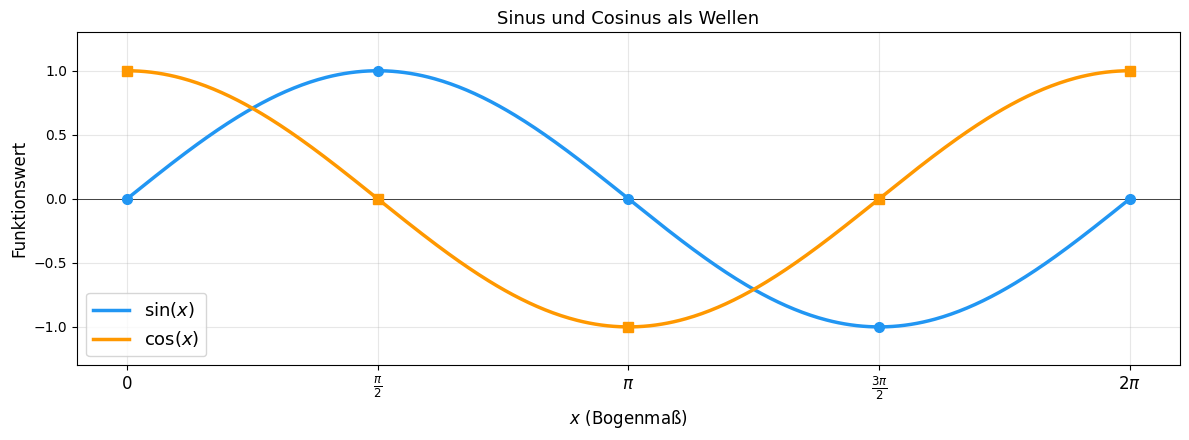

In [3]:
# --- Visualisierung: Sinus- und Cosinuswelle ---

x = np.linspace(0, 2 * np.pi, 500)
fig, ax = plt.subplots(figsize=(12, 4.5))

ax.plot(x, np.sin(x), color='#2196F3', linewidth=2.5, label='$\\sin(x)$')
ax.plot(x, np.cos(x), color='#FF9800', linewidth=2.5, label='$\\cos(x)$')

# Wichtige Punkte markieren
wichtige_winkel = [0, np.pi/2, np.pi, 3*np.pi/2, 2*np.pi]
labels = ['$0$', '$\\frac{\\pi}{2}$', '$\\pi$', '$\\frac{3\\pi}{2}$', '$2\\pi$']

for xw, lab in zip(wichtige_winkel, labels):
    ax.plot(xw, np.sin(xw), 'o', color='#2196F3', markersize=7, zorder=5)
    ax.plot(xw, np.cos(xw), 's', color='#FF9800', markersize=7, zorder=5)

ax.set_xticks(wichtige_winkel)
ax.set_xticklabels(labels, fontsize=12)
ax.set_yticks([-1, -0.5, 0, 0.5, 1])

ax.axhline(0, color='black', linewidth=0.5)
ax.grid(True, alpha=0.3)
ax.legend(fontsize=13)
ax.set_xlabel('$x$ (Bogenmaß)', fontsize=12)
ax.set_ylabel('Funktionswert', fontsize=12)
ax.set_title('Sinus und Cosinus als Wellen', fontsize=13)
ax.set_ylim(-1.3, 1.3)

plt.tight_layout()
plt.show()

## 3. Symmetrie und Vorzeichen

Der Taschenrechner gibt bei `asin(0.5)` oft nur einen Wert zurück ($30°$). Aber im Kreis gibt es oft einen zweiten Winkel, der den gleichen Sinuswert hat.

### Vorzeichen in den Quadranten

| Quadrant | Winkelbereich | $\sin$ | $\cos$ | $\tan$ |
|---|---|---|---|---|
| I   | $0°$-$90°$     | $+$ | $+$ | $+$ |
| II  | $90°$-$180°$   | $+$ | $-$ | $-$ |
| III | $180°$-$270°$  | $-$ | $-$ | $+$ |
| IV  | $270°$-$360°$  | $-$ | $+$ | $-$ |

### Wichtige Symmetrien
- **Sinus:** $\sin(180° - \alpha) = \sin(\alpha)$ - Spiegelung an der y-Achse im Kreis
- **Cosinus:** $\cos(360° - \alpha) = \cos(\alpha)$ - Spiegelung an der x-Achse im Kreis
- **Tangens:** $\tan(\alpha + 180°) = \tan(\alpha)$ - Periode $180°$

### Fundamentale Identität

Direkt aus dem Einheitskreis (Satz des Pythagoras auf das Dreieck mit Hypotenuse $r=1$):

$$\sin^2(\alpha) + \cos^2(\alpha) = 1$$

Daraus abgeleitet:
- $\sin^2(\alpha) = 1 - \cos^2(\alpha)$
- $\cos^2(\alpha) = 1 - \sin^2(\alpha)$

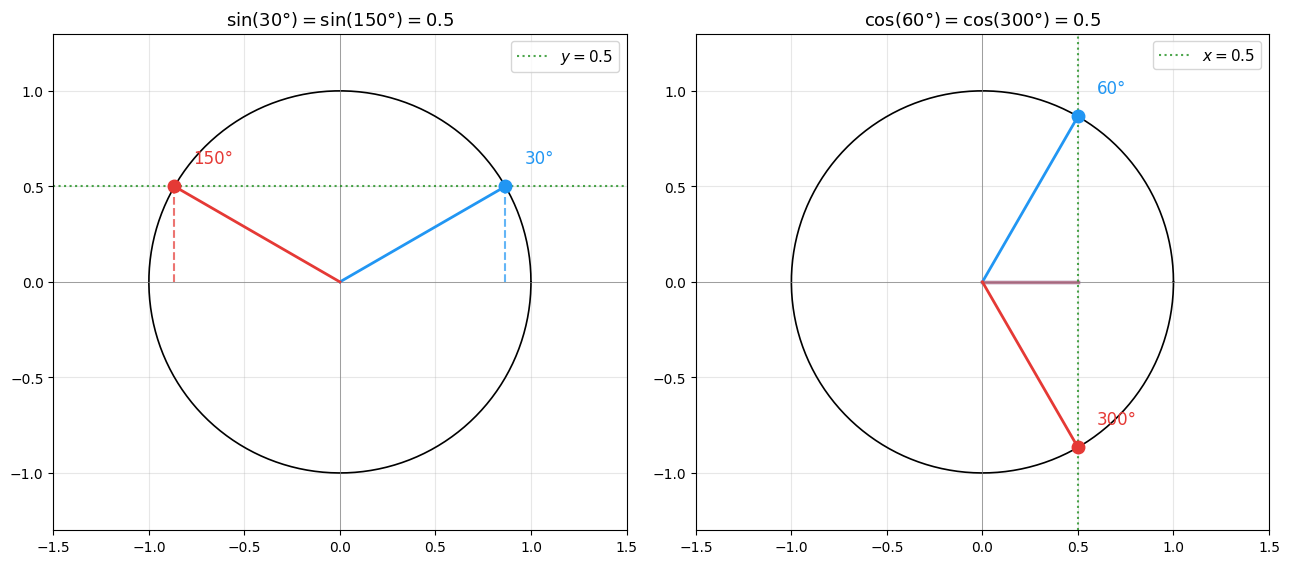

In [ ]:
# --- Visualisierung: Symmetrie am Einheitskreis ---

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

# --- Links: sin(30°) = sin(150°) ---
ax = axes[0]
theta = np.linspace(0, 2 * np.pi, 300)
ax.plot(np.cos(theta), np.sin(theta), 'k-', linewidth=1.2)
ax.axhline(0, color='grey', linewidth=0.5)
ax.axvline(0, color='grey', linewidth=0.5)

for winkel, farbe, name in [(30, '#2196F3', '30°'), (150, '#E53935', '150°')]:
    rad = np.radians(winkel)
    px, py = np.cos(rad), np.sin(rad)
    ax.plot(px, py, 'o', color=farbe, markersize=9, zorder=5)
    ax.plot([0, px], [0, py], '-', color=farbe, linewidth=2)
    ax.plot([px, px], [0, py], '--', color=farbe, linewidth=1.5, alpha=0.7)
    ax.annotate(f'{name}', xy=(px, py), xytext=(px + 0.1, py + 0.12), fontsize=12, color=farbe)

# Gemeinsame y-Höhe markieren
ax.axhline(0.5, color='green', linewidth=1.5, linestyle=':', alpha=0.7, label='$y = 0.5$')
ax.legend(fontsize=11)
ax.set_aspect('equal')
ax.set_xlim(-1.5, 1.5)
ax.set_ylim(-1.3, 1.3)
ax.grid(True, alpha=0.3)
ax.set_title('$\\sin(30°) = \\sin(150°) = 0.5$', fontsize=13)

# --- Rechts: cos(60°) = cos(300°) ---
ax = axes[1]
ax.plot(np.cos(theta), np.sin(theta), 'k-', linewidth=1.2)
ax.axhline(0, color='grey', linewidth=0.5)
ax.axvline(0, color='grey', linewidth=0.5)

for winkel, farbe, name in [(60, '#2196F3', '60°'), (300, '#E53935', '300°')]:
    rad = np.radians(winkel)
    px, py = np.cos(rad), np.sin(rad)
    ax.plot(px, py, 'o', color=farbe, markersize=9, zorder=5)
    ax.plot([0, px], [0, py], '-', color=farbe, linewidth=2)
    ax.plot([0, px], [0, 0], '-', color=farbe, linewidth=2.5, alpha=0.5)
    ax.annotate(f'{name}', xy=(px, py), xytext=(px + 0.1, py + 0.12), fontsize=12, color=farbe)

ax.axvline(0.5, color='green', linewidth=1.5, linestyle=':', alpha=0.7, label='$x = 0.5$')
ax.legend(fontsize=11)
ax.set_aspect('equal')
ax.set_xlim(-1.5, 1.5)
ax.set_ylim(-1.3, 1.3)
ax.grid(True, alpha=0.3)
ax.set_title('$\\cos(60°) = \\cos(300°) = 0.5$', fontsize=13)

plt.tight_layout()
plt.show()

## 4. Lösen trigonometrischer Gleichungen

Hier wird es algebraisch. Wir suchen alle $x$ in einem Intervall $[0, 2\pi]$ (bzw. $[0°, 360°]$).

### A. Einfache Gleichungen

**Beispiel:** $\sin(x) = 0{,}5$ im Intervall $[0, 2\pi]$

1. Taschenrechner / Tabelle: $x_1 = \arcsin(0{,}5) = \frac{\pi}{6}$ (= $30°$)
2. Symmetrie beachten: $x_2 = \pi - x_1 = \pi - \frac{\pi}{6} = \frac{5\pi}{6}$ (= $150°$)

**Lösung:** $x \in \left\{\frac{\pi}{6},\ \frac{5\pi}{6}\right\}$

### B. Substitution (komplexe Argumente)

**Beispiel:** $\sin(2x) = 0{,}5$ im Intervall $[0, 2\pi]$

1. **Substituiere** $u = 2x$. Neues Intervall: $u \in [0, 4\pi]$
2. Löse $\sin(u) = 0{,}5$: $u_1 = \frac{\pi}{6},\ u_2 = \frac{5\pi}{6}$
3. Periodenwiederholungen im erweiterten Intervall: $u_3 = \frac{\pi}{6} + 2\pi = \frac{13\pi}{6},\ u_4 = \frac{5\pi}{6} + 2\pi = \frac{17\pi}{6}$
4. **Rücksubstitution** $x = \frac{u}{2}$: $x \in \left\{\frac{\pi}{12},\ \frac{5\pi}{12},\ \frac{13\pi}{12},\ \frac{17\pi}{12}\right\}$

### C. Quadratische Form

**Beispiel:** $2\sin^2(x) - 1 = 0$

1. Umstellen: $\sin^2(x) = \frac{1}{2} \Rightarrow \sin(x) = \pm\frac{\sqrt{2}}{2}$
2. Alle Winkel mit $\sin(x) = \frac{\sqrt{2}}{2}$: $x = \frac{\pi}{4},\ \frac{3\pi}{4}$
3. Alle Winkel mit $\sin(x) = -\frac{\sqrt{2}}{2}$: $x = \frac{5\pi}{4},\ \frac{7\pi}{4}$

**Lösung:** $x \in \left\{\frac{\pi}{4},\ \frac{3\pi}{4},\ \frac{5\pi}{4},\ \frac{7\pi}{4}\right\}$

In [ ]:
# --- Verifikation: Trigonometrische Gleichungen lösen ---

import math

def trig_loesungen_sin(wert, intervall=(0, 2 * math.pi)):
    """Findet alle x in [a, b] mit sin(x) = wert."""
    lo, hi = intervall
    loesungen = []
    if abs(wert) > 1:
        return loesungen
    # Basislösung
    x0 = math.asin(wert)
    # Zwei Grundlösungen pro Periode
    basis = [x0, math.pi - x0]
    for b in basis:
        k = math.ceil((lo - b) / (2 * math.pi))
        while True:
            x = b + k * 2 * math.pi
            if x > hi + 1e-12:
                break
            if x >= lo - 1e-12:
                loesungen.append(round(x, 10))
            k += 1
    loesungen.sort()
    # Duplikate entfernen
    gefiltert = []
    for x in loesungen:
        if not gefiltert or abs(x - gefiltert[-1]) > 1e-9:
            gefiltert.append(x)
    return gefiltert

# --- Test: sin(x) = 0.5 ---
print("sin(x) = 0.5 in [0, 2π]:")
for x in trig_loesungen_sin(0.5):
    print(f"  x = {x:.6f} rad = {math.degrees(x):.1f}°  →  sin(x) = {math.sin(x):.6f}")

# --- Test: sin(2x) = 0.5  →  u = 2x in [0, 4π] ---
print("\nsin(2x) = 0.5 in [0, 2π]  (substituiere u = 2x):")
for u in trig_loesungen_sin(0.5, (0, 4 * math.pi)):
    x = u / 2
    print(f"  x = {x:.6f} rad = {math.degrees(x):.1f}°  →  sin(2x) = {math.sin(2*x):.6f}")

# --- Verifikation: sin²+cos² = 1 ---
print("\nFundamentale Identität: sin²(α) + cos²(α) = 1")
for grad in [0, 30, 45, 60, 90, 135, 210, 300]:
    rad = math.radians(grad)
    ergebnis = math.sin(rad)**2 + math.cos(rad)**2
    print(f"  α = {grad:>3}°:  {ergebnis:.15f}")

sin(x) = 0.5 in [0, 2π]:
  x = 0.523599 rad = 30.0°  →  sin(x) = 0.500000
  x = 2.617994 rad = 150.0°  →  sin(x) = 0.500000

sin(2x) = 0.5 in [0, 2π]  (substituiere u = 2x):
  x = 0.261799 rad = 15.0°  →  sin(2x) = 0.500000
  x = 1.308997 rad = 75.0°  →  sin(2x) = 0.500000
  x = 3.403392 rad = 195.0°  →  sin(2x) = 0.500000
  x = 4.450590 rad = 255.0°  →  sin(2x) = 0.500000

Fundamentale Identität: sin²(α) + cos²(α) = 1
  α =   0°:  1.000000000000000
  α =  30°:  1.000000000000000
  α =  45°:  1.000000000000000
  α =  60°:  1.000000000000000
  α =  90°:  1.000000000000000
  α = 135°:  1.000000000000000
  α = 210°:  1.000000000000000
  α = 300°:  1.000000000000000


---

## Verständnis-Check

**Aufgabe 1: Einheitskreis ablesen**

Bestimme ohne Taschenrechner (aus der Wertetabelle / dem Einheitskreis):

a) $\sin(90°)$ und $\cos(90°)$

b) $\sin(180°)$ und $\cos(180°)$

c) $\sin(330°)$ (Hinweis: $330° = 360° - 30°$)

d) $\cos(150°)$ (Hinweis: $150° = 180° - 30°$)

**Aufgabe 2: Bogenmaß**

Rechne um:

a) $120°$ in Bogenmaß

b) $\frac{5\pi}{4}$ in Grad

c) $315°$ in Bogenmaß

**Aufgabe 3: Gleichungen lösen**

Finde alle Lösungen im Intervall $[0°, 360°]$:

a) $\cos(x) = -\frac{1}{2}$

b) $\sin(x) = -\frac{\sqrt{2}}{2}$

c) $2\cos^2(x) - 1 = 0$ (Hinweis: quadratische Form)

**Aufgabe 4: Substitution**

Finde alle Lösungen im Intervall $[0°, 360°]$:

$\cos(2x) = 0$

### Lösungen

<details><summary>Lösung Aufgabe 1</summary>

a) $\sin(90°) = 1$, $\cos(90°) = 0$

b) $\sin(180°) = 0$, $\cos(180°) = -1$

c) $\sin(330°) = -\sin(30°) = -\frac{1}{2}$

d) $\cos(150°) = -\cos(30°) = -\frac{\sqrt{3}}{2}$

</details>

<details><summary>Lösung Aufgabe 2</summary>

a) $120° = 120 \cdot \frac{\pi}{180} = \frac{2\pi}{3}$

b) $\frac{5\pi}{4} = \frac{5 \cdot 180°}{4} = 225°$

c) $315° = 315 \cdot \frac{\pi}{180} = \frac{7\pi}{4}$

</details>

<details><summary>Lösung Aufgabe 3</summary>

a) $\cos(x) = -\frac{1}{2}$: $x \in \{120°, 240°\}$

b) $\sin(x) = -\frac{\sqrt{2}}{2}$: $x \in \{225°, 315°\}$

c) $2\cos^2(x) - 1 = 0 \Rightarrow \cos(x) = \pm\frac{\sqrt{2}}{2}$: $x \in \{45°, 135°, 225°, 315°\}$

</details>

<details><summary>Lösung Aufgabe 4</summary>

$\cos(2x) = 0$. Substituiere $u = 2x$, Intervall $u \in [0°, 720°]$.
$\cos(u) = 0 \Rightarrow u \in \{90°, 270°, 450°, 630°\}$
Rücksubstitution $x = u/2$: $x \in \{45°, 135°, 225°, 315°\}$

</details>

## Zusammenfassung

| Thema | Kernaussage |
|-------|-------------|
| Einheitskreis | $P = (\cos\alpha, \sin\alpha)$ auf dem Kreis mit $r=1$ |
| Bogenmaß | $\text{rad} = \text{deg} \cdot \frac{\pi}{180}$; Vollkreis = $2\pi$ |
| Graphen | Sinus und Cosinus sind periodische Wellen (Periode $2\pi$, Amplitude $1$) |
| Quadrantenregel | Vorzeichen von $\sin$/$\cos$ hängt vom Quadranten ab |
| Fundamentale Identität | $\sin^2(\alpha) + \cos^2(\alpha) = 1$ |
| Gleichungen lösen | Symmetrie beachten → oft 2 Lösungen; Substitution bei $\sin(nx)$ |



---

## Glossar

| Deutsch | Englisch |
|---------|----------|
| Einheitskreis | Unit circle |
| Bogenmaß | Radians |
| Gradmaß | Degrees |
| Periode | Period |
| Amplitude | Amplitude |
| Nullstelle | Zero / root |
| Symmetrie | Symmetry |
| Quadrant | Quadrant |
| Trigonometrische Gleichung | Trigonometric equation |
| Substitution | Substitution |
| Rücksubstitution | Back-substitution |
| Funktionsgraph | Function graph |
| Wertetabelle | Value table |
| Fundamentale Identität | Fundamental identity |